# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170019          # <-- your full roll number
NAME = "Gaurish"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170019   Name: Gaurish   Fingerprint: A9E1D1F3   Tickets: 16

Ticket_ID                                                                              Ticket_Text
      T01                                                            Version 2.0.1 crashes at 99%.
      T02                                     The e-mail crashes while opening. Please resolve it.
      T03                                                The printer won't print; it isn't jammed.
      T04          I can't open the laptop while uploading the file. It works on another computer.
      T05 MATLAB stopped responding when connected to campus Wi-Fi. The same problem occurs again.
      T06                   I can't open the password when connected to campus Wi-Fi. Please help.
      T07  I couldn't connect to the server when I use mobile hotspot. I have tried several times!
      T08             I tried restarting the projector since yesterday. Is there another solution?
      T09               Email 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
tickets = df["Ticket_Text"].tolist()
processed = [process_ticket(ticket) for ticket in tickets]

def as_tokens(value):
    if value is None:
        return []
    if isinstance(value, str):
        return value.split()
    return list(value)

# One row per ticket, followed by a TOTAL row.
q1_rows = []
for ticket_id, result in zip(df["Ticket_ID"], processed):
    q1_rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique tokens": sorted(set(result["tokens"])),
        "Final tokens": result["final"],
    })

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(r["sentences"]) for r in processed),
    "Tokens": sum(len(r["tokens"]) for r in processed),
    "Punctuation": sum(len(r["punct"]) for r in processed),
    "Stopwords": sum(len(r["stops"]) for r in processed),
    "Unique tokens": len(set(t for r in processed for t in r["tokens"])),
    "Final tokens": sum(len(r["final"]) for r in processed),
}
q1_table = pd.DataFrame(q1_rows + [total_row])
pd.set_option("display.max_colwidth", 100)
display(q1_table)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,T01,[Version 2.0.1 crashes at 99%.],"[version, 2.0.1, crashes, at, 99, %, .]","[%, .]",[at],"[%, ., 2.0.1, 99, at, crashes, version]","[version, 2.0.1, crashes, 99]"
1,T02,"[The e-mail crashes while opening., Please resolve it.]","[the, e-mail, crashes, while, opening, ., please, resolve, it, .]","[., .]","[the, while, it]","[., crashes, e-mail, it, opening, please, resolve, the, while]","[e-mail, crashes, opening, please, resolve]"
2,T03,[The printer won't print; it isn't jammed.],"[the, printer, wo, n't, print, ;, it, is, n't, jammed, .]","[;, .]","[the, it, is]","[., ;, is, it, jammed, n't, print, printer, the, wo]","[printer, wo, n't, print, n't, jammed]"
3,T04,"[I can't open the laptop while uploading the file., It works on another computer.]","[i, ca, n't, open, the, laptop, while, uploading, the, file, ., it, works, on, another, computer...","[., .]","[i, the, while, the, it, on]","[., another, ca, computer, file, i, it, laptop, n't, on, open, the, uploading, while, works]","[ca, n't, open, laptop, uploading, file, works, another, computer]"
4,T05,"[MATLAB stopped responding when connected to campus Wi-Fi., The same problem occurs again.]","[matlab, stopped, responding, when, connected, to, campus, wi-fi, ., the, same, problem, occurs,...","[., .]","[when, to, the, same, again]","[., again, campus, connected, matlab, occurs, problem, responding, same, stopped, the, to, when,...","[matlab, stopped, responding, connected, campus, wi-fi, problem, occurs]"
5,T06,"[I can't open the password when connected to campus Wi-Fi., Please help.]","[i, ca, n't, open, the, password, when, connected, to, campus, wi-fi, ., please, help, .]","[., .]","[i, the, when, to]","[., ca, campus, connected, help, i, n't, open, password, please, the, to, when, wi-fi]","[ca, n't, open, password, connected, campus, wi-fi, please, help]"
6,T07,"[I couldn't connect to the server when I use mobile hotspot., I have tried several times!]","[i, could, n't, connect, to, the, server, when, i, use, mobile, hotspot, ., i, have, tried, seve...","[., !]","[i, to, the, when, i, i, have]","[!, ., connect, could, have, hotspot, i, mobile, n't, server, several, the, times, to, tried, us...","[could, n't, connect, server, use, mobile, hotspot, tried, several, times]"
7,T08,"[I tried restarting the projector since yesterday., Is there another solution?]","[i, tried, restarting, the, projector, since, yesterday, ., is, there, another, solution, ?]","[., ?]","[i, the, is, there]","[., ?, another, i, is, projector, restarting, since, solution, the, there, tried, yesterday]","[tried, restarting, projector, since, yesterday, another, solution]"
8,T09,"[Email keeps disconnecting after resetting my password., Can you check this?]","[email, keeps, disconnecting, after, resetting, my, password, ., can, you, check, this, ?]","[., ?]","[after, my, can, you, this]","[., ?, after, can, check, disconnecting, email, keeps, my, password, resetting, this, you]","[email, keeps, disconnecting, resetting, password, check]"
9,T10,"[I cannot access the Python on my laptop., Is there another solution?]","[i, can, not, access, the, python, on, my, laptop, ., is, there, another, solution, ?]","[., ?]","[i, can, not, the, on, my, is, there]","[., ?, access, another, can, i, is, laptop, my, not, on, python, solution, the, there]","[access, python, laptop, another, solution]"


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens that are not real words may include numbers such as `99` and version strings such as `2.0.1`. These come from the original IT-support tickets, where numbers and software versions are preserved during preprocessing. Tokens like `n't`, `'s`, and `ca` can also arise from contractions when tokenization splits them into separate parts. In my sample output, `2.0.1` and `99` are retained as final tokens because they are not removed as stopwords or punctuation.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re
from collections import Counter

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

raw_texts = df["Ticket_Text"].tolist()
all_raw_text = "\n".join(raw_texts)

# Keep dotted version numbers and decimal values intact.
patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![A-Za-z0-9])\d+(?:[.,]\d+)*(?![A-Za-z0-9])",
    "Capitalized words": r"\b[A-Z][A-Za-z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b",
}

print("REGEX EXTRACTION FROM GENERATED TICKETS")
for label, pattern in patterns.items():
    matches = re.findall(pattern, all_raw_text)
    print(f"\n{label} ({len(matches)} matches):")
    print(matches)

email_pattern = r"(?i)\b[A-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Z0-9-]+(?:\.[A-Z0-9-]+)+\b"
url_pattern = r"(?i)\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[ -]?)?(?:\(?\d{2,5}\)?[ -]?)?\d{3,5}[ -]\d{4,6}(?!\w)"

def redact_identifiers(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, lambda m: m.group(0).rstrip(".,;:!?") and "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nREDACTION TEST_LINES")
for line in TEST_LINES:
    print("Original:", line)
    print("Redacted:", redact_identifiers(line))

print("\nREDACTION OF GENERATED TICKETS")
for line in raw_texts:
    print(redact_identifiers(line))

REGEX EXTRACTION FROM GENERATED TICKETS

Words longer than 5 letters (62 matches):
['Version', 'crashes', 'crashes', 'opening', 'Please', 'resolve', 'printer', 'jammed', 'laptop', 'uploading', 'another', 'computer', 'MATLAB', 'stopped', 'responding', 'connected', 'campus', 'problem', 'occurs', 'password', 'connected', 'campus', 'Please', 'couldn', 'connect', 'server', 'mobile', 'hotspot', 'several', 'restarting', 'projector', 'yesterday', 'another', 'solution', 'disconnecting', 'resetting', 'password', 'cannot', 'access', 'Python', 'laptop', 'another', 'solution', 'Printer', 'stopped', 'syncing', 'before', 'assignment', 'deadline', 'worked', 'yesterday', 'unable', 'laptop', 'Please', 'working', 'yesterday', 'yesterday', 'changed', 'installing', 'restarting', 'during', 'Please']

Numbers (8 matches):
['2.0.1', '99', '91', '98765', '43210', '0175', '239', '3201']

Capitalized words (34 matches):
['Version', 'The', 'Please', 'The', 'I', 'It', 'MATLAB', 'Wi', 'Fi', 'The', 'I', 'Wi', 'Fi', 

# Count capitalized matches that appear at the start of a sentence.
capitalized = re.findall(patterns["Capitalized words"], all_raw_text)
sentence_initial_words = []
for ticket in raw_texts:
    for sentence in sent_tokenize(ticket):
        match = re.match(r"\s*([A-Z][A-Za-z]*)", sentence)
        if match:
            sentence_initial_words.append(match.group(1))
initial_counts = Counter(sentence_initial_words)
sentence_initial_capitalized_matches = sum(initial_counts[w] for w in capitalized)
print(f"Capitalized-word matches: {len(capitalized)}")
print(f"Sentence-initial capitalized-word occurrences: {len(sentence_initial_words)}")
print(f"Occurrences likely capitalized only because they start a sentence: {len(sentence_initial_words)}")
print("Examples:", sentence_initial_words[:15])

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

# Ordered alternatives: URLs/emails/phones first, then versions/decimals,
# contractions, hyphenated words, ordinary words, and remaining numeric forms.
TOKEN_PATTERN = (
    r"https?://[^\s<>]+|www\.[^\s<>]+|"
    r"[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+|"
    r"\+?\d{1,3}[ -]\d{3,5}[ -]\d{4,6}|"
    r"\d+(?:[.,]\d+)+|"
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"
    r"[A-Za-z]+|\d+|[^\w\s]"
)
custom_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    """Tokenize text while preserving common multi-part items as single tokens."""
    return custom_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER ON TEST_LINES")
for line in TEST_LINES:
    print(line)
    print(my_tokenize(line))

comparison_rows = []
for ticket_id, text in zip(df["Ticket_ID"], tickets):
    custom = my_tokenize(text)
    standard = word_tokenize(text)
    comparison_rows.append({
        "Ticket_ID": ticket_id,
        "Custom tokens": custom,
        "word_tokenize tokens": standard,
        "Different?": custom != standard,
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
different_ticket_count = int(comparison_df["Different?"].sum())
print(f"Tickets tokenized differently: {different_ticket_count} / {len(df)}")

CUSTOM TOKENIZER ON TEST_LINES
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']


,Ticket_ID,Custom tokens,word_tokenize tokens,Different?
0,T01,"[Version, 2.0.1, crashes, at, 99, %, .]","[Version, 2.0.1, crashes, at, 99, %, .]",False
1,T02,"[The, e-mail, crashes, while, opening, ., Please, resolve, it, .]","[The, e-mail, crashes, while, opening, ., Please, resolve, it, .]",False
2,T03,"[The, printer, won't, print, ;, it, isn't, jammed, .]","[The, printer, wo, n't, print, ;, it, is, n't, jammed, .]",True
3,T04,"[I, can't, open, the, laptop, while, uploading, the, file, ., It, works, on, another, computer, .]","[I, ca, n't, open, the, laptop, while, uploading, the, file, ., It, works, on, another, computer...",True
4,T05,"[MATLAB, stopped, responding, when, connected, to, campus, Wi-Fi, ., The, same, problem, occurs,...","[MATLAB, stopped, responding, when, connected, to, campus, Wi-Fi, ., The, same, problem, occurs,...",False
5,T06,"[I, can't, open, the, password, when, connected, to, campus, Wi-Fi, ., Please, help, .]","[I, ca, n't, open, the, password, when, connected, to, campus, Wi-Fi, ., Please, help, .]",True
6,T07,"[I, couldn't, connect, to, the, server, when, I, use, mobile, hotspot, ., I, have, tried, severa...","[I, could, n't, connect, to, the, server, when, I, use, mobile, hotspot, ., I, have, tried, seve...",True
7,T08,"[I, tried, restarting, the, projector, since, yesterday, ., Is, there, another, solution, ?]","[I, tried, restarting, the, projector, since, yesterday, ., Is, there, another, solution, ?]",False
8,T09,"[Email, keeps, disconnecting, after, resetting, my, password, ., Can, you, check, this, ?]","[Email, keeps, disconnecting, after, resetting, my, password, ., Can, you, check, this, ?]",False
9,T10,"[I, cannot, access, the, Python, on, my, laptop, ., Is, there, another, solution, ?]","[I, can, not, access, the, Python, on, my, laptop, ., Is, there, another, solution, ?]",True


Tickets tokenized differently: 8 / 16


print(f"{different_ticket_count} of {len(df)} tickets are tokenized differently by my_tokenize and word_tokenize.")
print("The custom tokenizer keeps contractions, hyphenated terms, decimals/versions, URLs, emails and phone-like strings together where its pattern matches them. NLTK's word_tokenize often splits punctuation and parts of these expressions into separate tokens.")

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

unique_final_tokens = sorted(set(token for result in processed for token in result["final"]))
porter = PorterStemmer()
lancaster = LancasterStemmer()
# A deliberately simple suffix rule for this corpus. It is illustrative, not linguistic analysis.
regexp_stemmer = RegexpStemmer(r"(ing|edly|ed|ly|ies|s)$", min=4)
lemmatizer = WordNetLemmatizer()

def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

try:
    tagged = dict(pos_tag(unique_final_tokens))
except LookupError:
    tagged = {word: (word, "NN") for word in unique_final_tokens}

rows = []
for word in unique_final_tokens:
    pos = tagged.get(word, (word, "NN"))[1]
    wn_pos = penn_to_wordnet(pos)
    try:
        lemma = lemmatizer.lemmatize(word, pos=wn_pos)
    except LookupError:
        lemma = word
    row = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "Lemma (POS)": lemma,
        "POS": pos,
    }
    if len({row[k] for k in ["Porter", "Lancaster", "Regexp", "Lemma (POS)"]}) > 1:
        rows.append(row)

difference_df = pd.DataFrame(rows)
print(f"Unique final tokens: {len(unique_final_tokens)}; words with differing outputs: {len(difference_df)}")
display(difference_df)

Unique final tokens: 71; words with differing outputs: 43


,Word,Porter,Lancaster,Regexp,Lemma (POS),POS
0,access,access,access,acces,access,N
1,another,anoth,anoth,another,another,T
2,assignment,assign,assign,assignment,assignment,N
3,call,call,cal,call,call,B
4,campus,campu,camp,campu,campus,N
5,changed,chang,chang,chang,changed,B
6,computer,comput,comput,computer,computer,N
7,connected,connect,connect,connect,connected,B
8,crashes,crash,crash,crashe,crash,B
9,deadline,deadlin,deadlin,deadline,deadline,J


# Use examples from the generated comparison table when available.
if not difference_df.empty:
    lancaster_shortens = difference_df[difference_df["Lancaster"].str.len() < difference_df["Porter"].str.len()]
    if not lancaster_shortens.empty:
        ex = lancaster_shortens.iloc[0]
        print(f"Possible over-stemming: {ex['Word']!r} becomes {ex['Lancaster']!r} with Lancaster, which may remove too much of the word.")
    else:
        ex = difference_df.iloc[0]
        print(f"Potential over-stemming candidate: {ex['Word']!r} becomes {ex['Lancaster']!r} with Lancaster; inspect whether meaning is lost.")
    lemma_diff = difference_df[difference_df["Lemma (POS)"] != difference_df["Porter"]]
    if not lemma_diff.empty:
        ex = lemma_diff.iloc[0]
        print(f"Possible under-stemming / conservative normalization example: {ex['Word']!r} stays/changes to lemma {ex['Lemma (POS)']!r}, while Porter gives {ex['Porter']!r}.")
    else:
        print("No clear under-stemming example was found automatically; inspect the table for a word whose stem remains too close to the original.")
else:
    print("No differing outputs were found for this token set.")

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Tokens,Unique tokens,TTR
0,S1: all tokens,206,105,0.5097
1,S2: no punctuation,175,100,0.5714
2,S3: final tokens,107,71,0.6636
3,S4: S3 after Porter,107,67,0.6262


Top 10 words in S1


,Word,Frequency
0,.,23
1,the,13
2,i,10
3,n't,7
4,please,4
5,it,4
6,on,4
7,to,4
8,help,4
9,yesterday,4


Top 10 words in S3


,Word,Frequency
0,n't,7
1,please,4
2,help,4
3,yesterday,4
4,laptop,3
5,another,3
6,tried,3
7,lms,3
8,crashes,2
9,printer,2


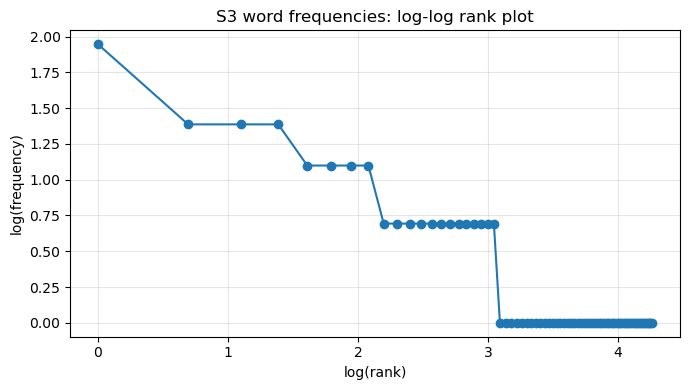

Top 5 bigrams in S1


,Bigram,Frequency
0,. i,6
1,. please,4
2,. the,3
3,please help,3
4,help .,3


Top 5 bigrams in S3


,Bigram,Frequency
0,please help,3
1,ca n't,2
2,n't open,2
3,connected campus,2
4,campus wi-fi,2


In [9]:
import math
import matplotlib.pyplot as plt
from nltk.util import ngrams

S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in processed for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

def corpus_summary(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    return {"Corpus": name, "Tokens": total, "Unique tokens": unique, "TTR": round(ttr, 4)}

stats_df = pd.DataFrame([
    corpus_summary("S1: all tokens", S1),
    corpus_summary("S2: no punctuation", S2),
    corpus_summary("S3: final tokens", S3),
    corpus_summary("S4: S3 after Porter", S4),
])
display(stats_df)

print("Top 10 words in S1")
display(pd.DataFrame(Counter(S1).most_common(10), columns=["Word", "Frequency"]))
print("Top 10 words in S3")
display(pd.DataFrame(Counter(S3).most_common(10), columns=["Word", "Frequency"]))

freq_s3 = Counter(S3)
ranked = sorted(freq_s3.values(), reverse=True)
ranks = list(range(1, len(ranked) + 1))
plt.figure(figsize=(7, 4))
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in ranked], marker="o", linestyle="-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3 word frequencies: log-log rank plot")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

def top_bigrams(tokens, n=5):
    return Counter(zip(tokens, tokens[1:])).most_common(n)

print("Top 5 bigrams in S1")
display(pd.DataFrame([{"Bigram": f"{a} {b}", "Frequency": count}
                      for (a, b), count in top_bigrams(S1)]))
print("Top 5 bigrams in S3")
display(pd.DataFrame([{"Bigram": f"{a} {b}", "Frequency": count}
                      for (a, b), count in top_bigrams(S3)]))

s1_ttr = stats_df.loc[stats_df["Corpus"] == "S1: all tokens", "TTR"].iloc[0]
s2_ttr = stats_df.loc[stats_df["Corpus"] == "S2: no punctuation", "TTR"].iloc[0]
s3_ttr = stats_df.loc[stats_df["Corpus"] == "S3: final tokens", "TTR"].iloc[0]
s4_ttr = stats_df.loc[stats_df["Corpus"] == "S4: S3 after Porter", "TTR"].iloc[0]
print(f"S1 TTR={s1_ttr:.4f}, S2 TTR={s2_ttr:.4f}, S3 TTR={s3_ttr:.4f}, S4 TTR={s4_ttr:.4f}.")
print("TTR is unique-token count divided by total-token count. Removing punctuation and stopwords changes both the vocabulary and total count. Porter stemming merges related forms such as 'crashes' and 'crash' into a shared stem, usually reducing the number of unique forms and often lowering TTR. The exact direction depends on this generated ticket corpus.")